## THƯ VIỆN 


In [28]:
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import os
from torch.utils.data import Dataset, DataLoader

## KIỂM TRA THIẾT BỊ 

In [29]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


## LOAD DATA


In [30]:
import pandas as pd

train = pd.read_csv("../data_processed/train_processed.csv")
test = pd.read_csv("../data_processed/test_processed.csv")

## TÁCH FEATURE VÀ TARGET

In [31]:
# 1. SỬA LẠI ĐOẠN TÁCH TRAIN/VALID (Bỏ dùng train_test_split)
train_df = train[train["split"] == "train"]
valid_df = train[train["split"] == "validation"]
drop_cols = ["Id", "SalePrice", "SalePrice_log", "split"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["SalePrice_log"]

X_valid = valid_df.drop(columns=drop_cols)
y_valid = valid_df["SalePrice_log"]

## Kiểm tra 
print("X shape:", X_train.shape)
print("y shape:", y_train.shape)

X shape: (1168, 314)
y shape: (1168,)


## Chuyển sang Pytorch Tensor 

In [33]:
X_train_tensor = torch.tensor(
    X_train.values,
    dtype=torch.float32
)

X_valid_tensor = torch.tensor(
    X_valid.values,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.values,
    dtype=torch.float32
)

y_valid_tensor = torch.tensor(
    y_valid.values,
    dtype=torch.float32
)
# Kiểm tra 
print("X_train_tensor:", X_train_tensor.shape)
print("y_train_tensor:", y_train_tensor.shape)

print("X dtype:", X_train_tensor.dtype)
print("y dtype:", y_train_tensor.dtype)

X_train_tensor: torch.Size([1168, 314])
y_train_tensor: torch.Size([1168])
X dtype: torch.float32
y dtype: torch.float32


## Định nghĩa Dataset 

In [34]:
class HousePriceDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = X.float()
        self.y = None

        if y is not None:
            self.y = y.float()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is not None:
            return self.X[idx], self.y[idx]

        return self.X[idx]

## Định nghĩa mô hình MLP 

In [35]:
# CẬP NHẬT MÔ HÌNH MLP
class MLPRegressor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),     # Tăng Dropout lớp đầu lên 0.3

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

input_dim = X_train_tensor.shape[1]
model = MLPRegressor(input_dim=input_dim).to(device)
print(model)


MLPRegressor(
  (network): Sequential(
    (0): Linear(in_features=314, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)


## Tạo Dataset 

In [36]:
train_dataset = HousePriceDataset(
    X_train_tensor,
    y_train_tensor
)

valid_dataset = HousePriceDataset(
    X_valid_tensor,
    y_valid_tensor
)
# Kiểm tra 1 mẫu 
sample_X, sample_y = train_dataset[0]

print("Sample X shape:", sample_X.shape)
print("Sample y:", sample_y)

Sample X shape: torch.Size([314])
Sample y: tensor(12.2477)


## Tạo Dataloader

In [37]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False
)
# kiểm tra 1 batch 
X_batch, y_batch = next(iter(train_loader))

print("Batch X shape:", X_batch.shape)
print("Batch y shape:", y_batch.shape)

Batch X shape: torch.Size([32, 314])
Batch y shape: torch.Size([32])


## Khai báo loss và optimizer

In [38]:
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

epochs = 300
patience = 30
patience_counter = 0
best_valid_loss = float('inf')

## Training và Validation

In [39]:
train_losses = []
valid_losses = []

os.makedirs("../models", exist_ok=True)
model_path = "../models/mlp_model_best.pth"

for epoch in range(epochs):
    # --- Training ---
    model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        predictions = model(X_batch).squeeze(-1)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)

    # --- Validation ---
    model.eval()
    valid_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in valid_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            predictions = model(X_batch).squeeze(-1)
            loss = criterion(predictions, y_batch)
            valid_loss += loss.item()
    valid_loss /= len(valid_loader)

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    # Cập nhật Scheduler
    scheduler.step(valid_loss)
    current_lr = optimizer.param_groups[0]['lr']

    print(f"Epoch [{epoch + 1:03d}/{epochs}] | Train Loss: {train_loss:.4f} | Valid Loss: {valid_loss:.4f} | LR: {current_lr:.6f}")

    # --- Early Stopping & Save Best Model ---
    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        patience_counter = 0
        # Lưu checkpoint tốt nhất
        torch.save({
            "model_state_dict": model.state_dict(),
            "input_dim": input_dim
        }, model_path)
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print(f"\\nEarly stopping kích hoạt tại epoch {epoch + 1}! Loss tốt nhất: {best_valid_loss:.4f}")
        break

print(f"\\nMô hình tốt nhất đã được lưu tại: {model_path}")

Epoch [001/300] | Train Loss: 51.1255 | Valid Loss: 3.3120 | LR: 0.010000
Epoch [002/300] | Train Loss: 3.5941 | Valid Loss: 0.9341 | LR: 0.010000
Epoch [003/300] | Train Loss: 2.5092 | Valid Loss: 0.6593 | LR: 0.010000
Epoch [004/300] | Train Loss: 2.5039 | Valid Loss: 0.9597 | LR: 0.010000
Epoch [005/300] | Train Loss: 2.2590 | Valid Loss: 0.7282 | LR: 0.010000
Epoch [006/300] | Train Loss: 1.8745 | Valid Loss: 0.9923 | LR: 0.010000
Epoch [007/300] | Train Loss: 1.8148 | Valid Loss: 0.4686 | LR: 0.010000
Epoch [008/300] | Train Loss: 1.8524 | Valid Loss: 0.4347 | LR: 0.010000
Epoch [009/300] | Train Loss: 1.6993 | Valid Loss: 0.4394 | LR: 0.010000
Epoch [010/300] | Train Loss: 1.4563 | Valid Loss: 0.5645 | LR: 0.010000
Epoch [011/300] | Train Loss: 1.4836 | Valid Loss: 0.2869 | LR: 0.010000
Epoch [012/300] | Train Loss: 1.3970 | Valid Loss: 0.3130 | LR: 0.010000
Epoch [013/300] | Train Loss: 1.3176 | Valid Loss: 0.3048 | LR: 0.010000
Epoch [014/300] | Train Loss: 1.4150 | Valid Loss:

## Loss Grapht

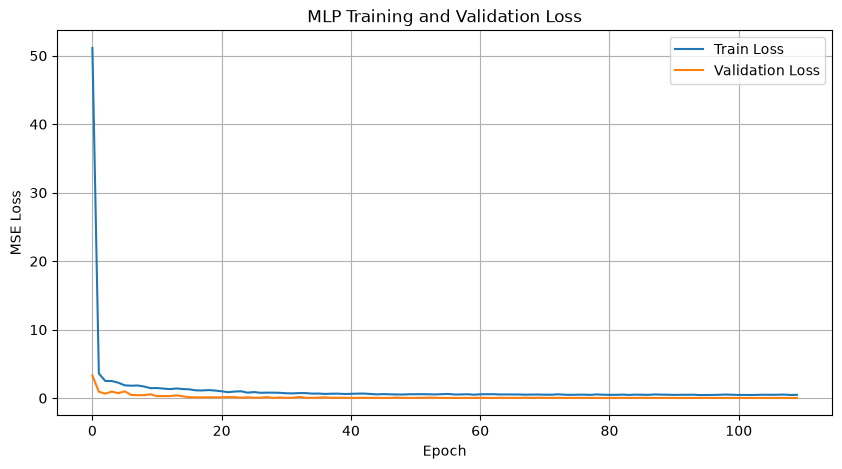

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(valid_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("MLP Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

## Kiểm tra khả năng dự đoán 

In [41]:
model.eval()

with torch.no_grad():
    sample_input = X_valid_tensor[:5].to(device)
    sample_prediction = model(sample_input).squeeze(-1)

print("Predictions:")
print(sample_prediction.cpu())

print("\nActual values:")
print(y_valid_tensor[:5])

Predictions:
tensor([11.6627, 11.8740, 11.2706, 11.4843, 12.0309])

Actual values:
tensor([11.7906, 11.7745, 11.1346, 10.5967, 12.1002])
